# Prediksi Energi dengan Model Regresi

*Referensi: Onno W. Purbo, IoT Terintegrasi dengan Machine Learning & Data Analytics, Bab 8.*

Notebook ini membandingkan Linear Regression, Ridge Regression, dan Random Forest untuk memprediksi daya 10 menit ke depan.

> **Pertanyaan ML:** model mana yang menghasilkan error paling rendah pada test set?

## Tahapan Analisis

1. Melatih tiga model regresi pada data yang sama.
2. Membandingkan MAE dan RMSE pada validation dan test set.
3. Memeriksa prediksi model secara visual.
4. Memilih model dengan performa test yang paling baik.

Target yang diprediksi adalah daya listrik dalam watt.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /Users/sulhanf/Second Brain/01 Projects/04 Katana/iot-ml-book


## 1. Linear Regression

Model linear digunakan sebagai baseline ML yang sederhana dan mudah dijelaskan.

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/regression_linear_energy.py"], capture_output=True, text=True, check=True)
print(r.stdout)

=== LINEAR REGRESSION ===
Validation MAE : 16.00800511115472
Validation RMSE : 23.480113312283923
Test MAE        : 17.3044866330361
Test RMSE       : 27.20018243938499
Prediksi test disimpan ke: data/processed/regression_energy/pred_linear_test.csv



## 2. Ridge Regression

Ridge menambahkan regularisasi L2 untuk membatasi koefisien model.

In [3]:
r = subprocess.run([sys.executable, "scripts/regression_ridge_energy.py"], capture_output=True, text=True, check=True)
print(r.stdout)

=== RIDGE REGRESSION ===
Validation MAE : 16.0053935682427
Validation RMSE: 23.479769329903654
Test MAE       : 17.305370165244153
Test RMSE      : 27.19975369792559
[SUKSES] Prediksi test disimpan ke: data/processed/regression_energy/pred_ridge_test.csv



## 3. Random Forest Regressor

Random Forest digunakan untuk menguji apakah pola non-linear dapat mengurangi error.

In [4]:
r = subprocess.run([sys.executable, "scripts/regression_rf_energy.py"], capture_output=True, text=True, check=True)
print(r.stdout)

=== RANDOM FOREST REGRESSOR ===
Validation MAE : 14.822698018610817
Validation RMSE : 22.156767952291787
Test MAE        : 18.706574739829342
Test RMSE       : 27.25613179132821
Prediksi test disimpan ke: data/processed/regression_energy/pred_rf_test.csv



> ### Checkpoint 1 — Semua Model Selesai Dilatih
> Linear Regression, Ridge Regression, dan Random Forest telah dievaluasi pada validation dan test set yang sama.

## 4. Perbandingan Prediksi

Grafik menampilkan aktual, Linear Regression, dan Random Forest pada 120 sampel test pertama. Ridge tidak ditampilkan karena prediksinya hampir sama dengan Linear Regression.

Figure(1200x500)



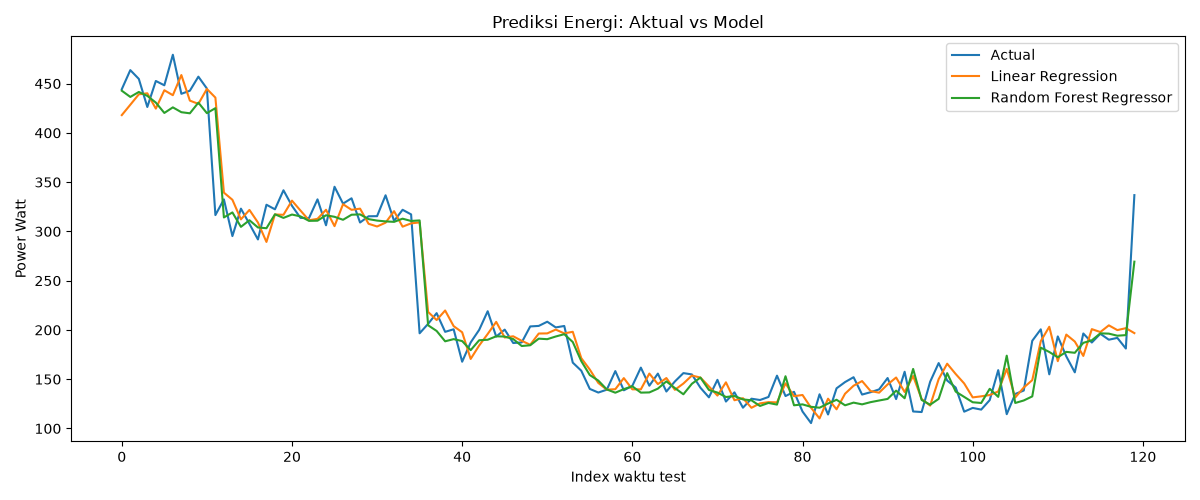

In [5]:
r = subprocess.run([sys.executable, "scripts/plot_regression_predictions.py"], capture_output=True, text=True, check=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/regression_predictions_compare.png")

## 5. Perbandingan Metrik Test

In [6]:
import pandas as pd, numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import Markdown, display
y = pd.read_csv("data/processed/regression_energy/y_test.csv").squeeze()
model_files = {
    "Linear Regression": "pred_linear_test.csv",
    "Ridge Regression": "pred_ridge_test.csv",
    "Random Forest": "pred_rf_test.csv",
}
rows = []
for nama, f in model_files.items():
    p = pd.read_csv("data/processed/regression_energy/" + f).iloc[:, -1]
    rows.append({
        "Model": nama,
        "MAE (W)": mean_absolute_error(y, p),
        "RMSE (W)": np.sqrt(mean_squared_error(y, p)),
    })
metrics = pd.DataFrame(rows).sort_values("MAE (W)").reset_index(drop=True)
display(metrics.style.format({"MAE (W)": "{:.3f}", "RMSE (W)": "{:.3f}"}).hide(axis="index"))
best = metrics.iloc[0]
display(Markdown(
    f"> ### Checkpoint 2 — Model Terbaik pada Test Set\n"
    f"> **{best['Model']}** menghasilkan MAE terendah, yaitu **{best['MAE (W)']:.3f} W**."
))

Model,MAE (W),RMSE (W)
Linear Regression,17.304,27.200
Ridge Regression,17.305,27.200
Random Forest,18.707,27.256


> ### Checkpoint 2 — Model Terbaik pada Test Set
> **Linear Regression** menghasilkan MAE terendah, yaitu **17.304 W**.

## Penutup

Linear Regression dan Ridge menghasilkan MAE test sekitar **17,3 W**. Random Forest lebih baik pada validation, tetapi MAE test-nya sekitar **18,8 W**. Perbedaan ini menunjukkan bahwa Random Forest tidak memberikan peningkatan pada data test.

> **Kesimpulan:** Linear Regression dipilih karena memiliki MAE test terendah serta lebih sederhana dan mudah dijelaskan.